# US30

### 1. US13 Graph - Linear and Quadratic Regression

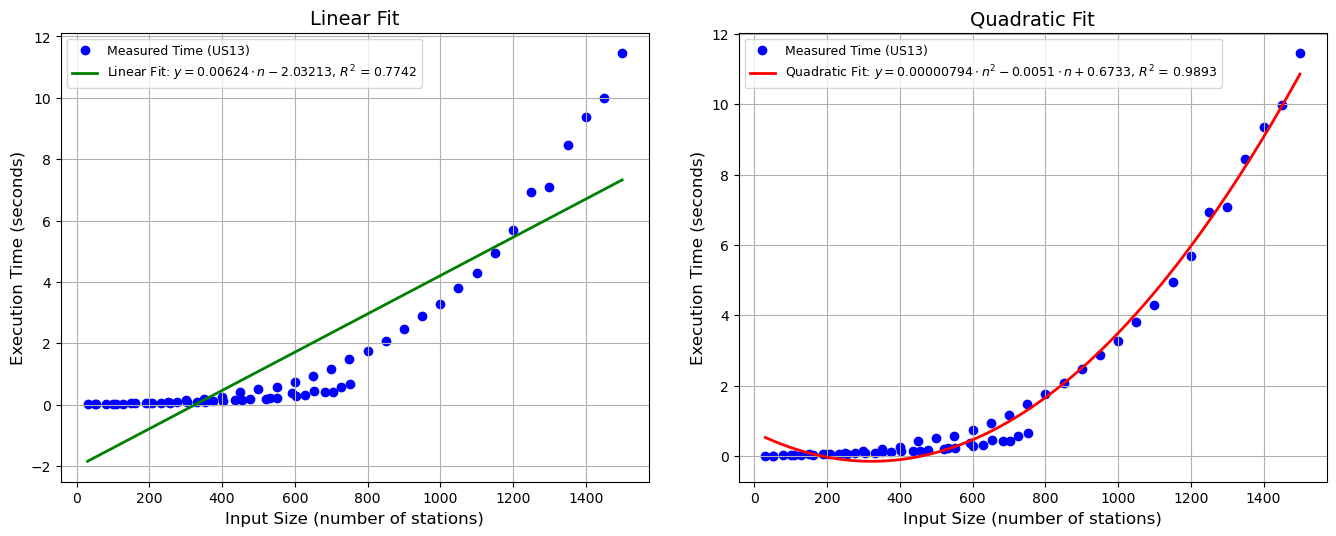

In [72]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
import pandas as pd

# Models
def linear(n, a, b):
    return a * n + b

def quadratic(n, a, b, c):
    return a * n**2 + b * n + c

# R² function
def calculate_r_squared(y_true, y_pred):
    residuals = y_true - y_pred
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

# Read and sort data
def read_data(filename):
    df = pd.read_csv(filename)
    sizes = df['size'].values
    times = df['time'].values
    sorted_indices = np.argsort(sizes)
    return sizes[sorted_indices], times[sorted_indices]

# Load data
sizes_us13, times_us13 = read_data('files/us13_execution_times.csv')

# Fit models
params_linear_us13, _ = curve_fit(linear, sizes_us13, times_us13)
fitted_linear_us13 = linear(sizes_us13, *params_linear_us13)
r2_linear_us13 = calculate_r_squared(times_us13, fitted_linear_us13)

params_quadratic_us13, _ = curve_fit(quadratic, sizes_us13, times_us13)
fitted_quadratic_us13 = quadratic(sizes_us13, *params_quadratic_us13)
r2_quadratic_us13 = calculate_r_squared(times_us13, fitted_quadratic_us13)

# Coefficients
a_lin, b_lin = params_linear_us13
a_quad, b_quad, c_quad = params_quadratic_us13

# Format parts of the quadratic equation with conditional signs
b_sign = "+" if b_quad >= 0 else "-"
c_sign = "+" if c_quad >= 0 else "-"

# Plotting
plt.figure(figsize=(14, 6))
n_plot = np.linspace(min(sizes_us13), max(sizes_us13), 200)

# Linear fit plot
plt.subplot(1, 2, 1)
plt.plot(sizes_us13, times_us13, 'o', label='Measured Time (US13)', color='blue', markersize=6, zorder=1)
plt.plot(n_plot, linear(n_plot, *params_linear_us13), '-', color='green', linewidth=2,
         label=rf'Linear Fit: $y = {a_lin:.5f} \cdot n { "+" if b_lin >= 0 else "-" } {abs(b_lin):.5f}$, $R^2$ = {r2_linear_us13:.4f}', zorder=2)
plt.xlabel('Input Size (number of stations)', fontsize=12)
plt.ylabel('Execution Time (seconds)', fontsize=12)
plt.title('Linear Fit', fontsize=14)
plt.grid(True)
plt.legend(fontsize=9, loc='upper left')

# Quadratic fit plot
plt.subplot(1, 2, 2)
plt.plot(sizes_us13, times_us13, 'o', label='Measured Time (US13)', color='blue', markersize=6, zorder=1)
plt.plot(n_plot, quadratic(n_plot, *params_quadratic_us13), '-', color='red', linewidth=2,
         label=rf'Quadratic Fit: $y = {a_quad:.8f} \cdot n^2 {b_sign} {abs(b_quad):.4f} \cdot n {c_sign} {abs(c_quad):.4f}$, $R^2$ = {r2_quadratic_us13:.4f}', zorder=2)
plt.xlabel('Input Size (number of stations)', fontsize=12)
plt.ylabel('Execution Time (seconds)', fontsize=12)
plt.title('Quadratic Fit', fontsize=14)
plt.grid(True)
plt.legend(fontsize=9, loc='upper left')

plt.tight_layout(pad=3.0)
plt.show()


### 2. US14 Graph - Linear Regression

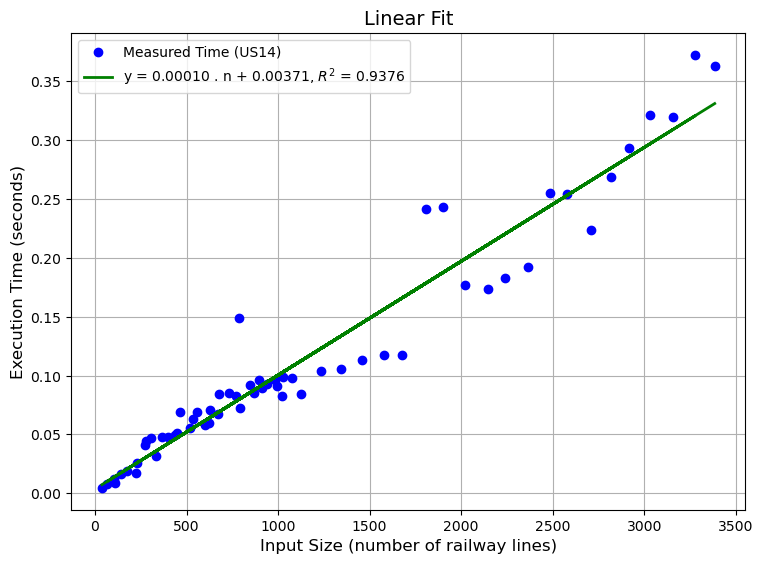

In [73]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit


# Function to read data from the file
def read_data(filename):
    df = pd.read_csv(filename, delimiter=',')
    sizes = df['size'].values
    times = df['time'].values
    return np.array(sizes), np.array(times)

# Theoretical functions
def linear(n, a, b):
    return a * n + b

# Read US14 data
sizes, times = read_data('files/us14_execution_times.csv')

# Choose the expected theoretical complexity (adjustable)
fit_func = linear  # Can be adjusted to 'nlogn' or 'quadratic'

# Curve fitting
params, _ = curve_fit(fit_func, sizes, times)
fitted_times = fit_func(sizes, *params)

# Calculate R^2 (coefficient of determination)
residuals = times - fitted_times
ss_res = np.sum(residuals**2)
ss_tot = np.sum((times - np.mean(times))**2)
r_squared = 1 - (ss_res / ss_tot)

# Coefficients
a, b = params

# Plot
plt.figure(figsize=(8, 6))  # Adjusting figure size for better visibility


plt.plot(sizes, times, 'o', label='Measured Time (US14)', color='blue', markersize=6)
plt.plot(sizes, fitted_times, '-', color='green', linewidth=2,
         label='y = {:.5f} . n + {:.5f}, $R^2$ = {:.4f}'.format(a, b, r_squared))
plt.xlabel('Input Size (number of railway lines)', fontsize=12)
plt.ylabel('Execution Time (seconds)', fontsize=12)
plt.title('Linear Fit', fontsize=14)
plt.grid(True)
plt.legend(fontsize=10, loc='upper left')
plt.tight_layout(pad=2.0)

plt.show()


# US31

In [74]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from scipy.stats import t

# Load dataset
df = pd.read_csv("files/Stations_Data.csv", sep=";")

# Replace comma with dot and convert numeric columns
for col in df.columns[4:]:
    df[col] = df[col].astype(str).str.replace(",", ".").astype(float)

# Display available stations
stations = df["Station"].unique()
print("Available stations:")
for idx, station in enumerate(stations, 1):
    print(f"{idx}. {station}")

# Select station by number
station_choice = int(input("\nSelect station by number: "))
station = stations[station_choice - 1]  # Convert choice to the corresponding station name
print(f"\nSelected station: {station}")

# Display available years for the chosen station
years = df[df["Station"] == station]["Year"].unique()
print("\nAvailable years:")
for idx, year in enumerate(years, 1):
    print(f"{idx}. {year}")

# Select year by number
year_choice = int(input("\nSelect year by number: "))
year = years[year_choice - 1]  # Convert choice to the corresponding year
print(f"\nSelected year: {year}")

# Filter data for the selected station and year
data = df[(df["Station"] == station) & (df["Year"] == year)]

# Define cargo columns and corresponding units
cargo_cols = ['Iron', 'Coal', 'Prata', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle', 'Passengers', 'Mail']
units = {
    'Iron': 'tons',
    'Coal': 'tons',
    'Prata': 'tons',
    'Vegetables': 'tons',
    'Cereals': 'tons',
    'Wool': 'tons',
    'Coffee': 'tons',
    'Cattle': 'tons',
    'Passengers': 'number',
    'Mail': 'tons'
}
revenue = data['Revenues']

# Compute correlation with revenue
correlations = {}
for cargo in cargo_cols:
    corr = data[cargo].corr(revenue)
    correlations[cargo] = corr

# Find cargo with highest absolute correlation
best_cargo = max(correlations, key=lambda k: abs(correlations[k]))
unit = units[best_cargo]  # Get the unit of the most correlated cargo
print(f"\nCargo most correlated with revenue: {best_cargo} (correlation = {correlations[best_cargo]:.4f})")
print(f"Unit for {best_cargo}: {unit}")

# Prepare data for regression
X = data[[best_cargo]].values
y = revenue.values
n = len(X)

# Fit linear regression
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
beta0 = model.intercept_
beta1 = model.coef_[0]

print(f"\nRegression model: ŷ = {beta0:.4f} + {beta1:.4f} × {best_cargo} ({unit} for cargo and in millions € for revenue)")

# Calculate residuals and s² (variance of residuals)
residuals = y - y_pred
s2 = np.sum(residuals ** 2) / (n - 2)
print(f"Residual variance (s²) in Millions (€): {s2:.4f}")

# Calculate standard error of beta1 and beta0
X_mean = X.mean()
Sxx = np.sum((X - X_mean) ** 2)
SE_beta1 = np.sqrt(s2 / Sxx)
SE_beta0 = np.sqrt(s2 * (1 / n + X_mean ** 2 / Sxx))

print(f"Standard error of β0 (in Millions €): {SE_beta0:.4f}")
print(f"Standard error of β1 (in Millions € per {unit}): {SE_beta1:.4f}")

# Get January value for prediction (January data from the selected year)
january_value = df[(df["Station"] == station) & (df["Year"] == year) & (df["Month"] == 1)][best_cargo].values[0]
increased_value = january_value * 1.10
print(f"\nOriginal {best_cargo} in January: {january_value:.2f} {unit}")
print(f"{best_cargo} with 10% increase: {increased_value:.2f} {unit}")

# Predict revenue for increased cargo
y0_pred = model.predict([[increased_value]])[0]
print(f"Predicted revenue for increased cargo: {y0_pred:.2f} Millions (€)")

# Calculate confidence interval for predicted revenue
t_critical = t.ppf(0.975, df=n - 2)  # 95% confidence level

# Compute margin of error
margin_error = t_critical * np.sqrt(s2 * (1 + 1/n + ((increased_value - X_mean) ** 2) / Sxx))
lower_bound = y0_pred - margin_error
upper_bound = y0_pred + margin_error

print(f"95% confidence interval for expected revenue: [{lower_bound:.2f}, {upper_bound:.2f}] Millions (€)")


Available stations:
1. Stuttgart
2. Frankfurt
3. Hannover
4. Hamburg
5. Berlin

Selected station: Stuttgart

Available years:
1. 2015
2. 2016
3. 2017
4. 2018
5. 2019
6. 2020
7. 2021
8. 2022
9. 2023
10. 2024

Selected year: 2016

Cargo most correlated with revenue: Prata (correlation = 0.6252)
Unit for Prata: tons

Regression model: ŷ = 801.2883 + 0.5790 × Prata (tons for cargo and in millions € for revenue)
Residual variance (s²) in Millions (€): 16780.3949
Standard error of β0 (in Millions €): 161.1017
Standard error of β1 (in Millions € per tons): 0.2286

Original Prata in January: 404.37 tons
Prata with 10% increase: 444.81 tons
Predicted revenue for increased cargo: 1058.85 Millions (€)
95% confidence interval for expected revenue: [734.38, 1383.33] Millions (€)
